# 04 — Model Comparison and Class-Imbalance Strategies

**Question.** Do more flexible models (Random Forest, XGBoost), or any of the standard class-imbalance techniques, produce better probability-of-default estimates than the Logistic Regression baseline?

**Protocol (unchanged from Phase 2)**
- Hyperparameters are tuned by 5-fold stratified CV on the training set.
- Every imbalance strategy reuses its base model's tuned hyperparameters and changes **only** the strategy.
- Resampling runs inside an `imblearn` pipeline, so it is applied to training folds only and never to validation data.
- All figures below are validation results, read from `artifacts/metrics/`. The test set is not used.

In [1]:
import json
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from credit_risk.config import load_config, resolve_path
BLUE, ORANGE, AQUA, YELLOW, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9a9a", "#1f1f1f", "#6b6b6b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "axes.axisbelow": True, "figure.dpi": 110})
FIG_DIR = resolve_path("reports/figures")
M = resolve_path("artifacts/metrics")
pd.set_option("display.width", 200); pd.set_option("display.precision", 4); pd.set_option("display.max_rows", 60)
SKIP = {"summary", "comparisons", "selection"}
records = {p.stem: r for p in M.glob("*.json") if p.stem not in SKIP
           for r in [json.loads(p.read_text())] if r.get("evaluated_on") == "validation" and "model" in r}
summary = pd.DataFrame(json.loads((M / "summary.json").read_text())["models"]).set_index("model")
comparisons = pd.DataFrame(json.loads((M / "comparisons.json").read_text()))

def family(name):
    spec = records[name]["specification"]
    return spec.get("inherits_from", name).split("__")[0] if spec.get("inherits_from") else name

def strategy(name):
    rec = records[name]; spec = rec["specification"]; p = spec.get("params", {})
    if rec["calibration"] != "none": return f"calibrated ({rec['calibration']})"
    if spec.get("sampler"): return spec["sampler"]["name"]
    if p.get("class_weight") or p.get("scale_pos_weight"): return "class weights"
    if spec["estimator"] in {"balanced_random_forest", "easy_ensemble", "rusboost"}: return "imbalance-aware ensemble"
    return "none"

cols = ["sampler", "inherits_from", "cv_average_precision", "cv_average_precision_std", "roc_auc", "pr_auc", "brier",
        "expected_calibration_error", "mean_predicted_pd", "recall", "precision", "flagged_rate",
        "capacity_recall", "capacity_precision", "capacity_f2", "fit_seconds"]
summary.sort_values("pr_auc", ascending=False)[cols]

,sampler,inherits_from,cv_average_precision,cv_average_precision_std,roc_auc,pr_auc,brier,expected_calibration_error,mean_predicted_pd,recall,precision,flagged_rate,capacity_recall,capacity_precision,capacity_f2,fit_seconds
model,,,,,,,,,,,,,,,,
xgboost,none,NaN,0.5693,0.0175,0.7879,0.5631,0.1333,0.0152,0.2186,0.8493,0.3332,0.5637,0.6217,0.4696,0.5839,97.50
xgboost__sigmoid,none,xgboost,NaN,NaN,0.7879,0.5631,0.1340,0.0272,0.2191,0.8312,0.3470,0.5298,0.6262,0.4617,0.5846,5.76
xgboost_tomek_links,tomek_links,xgboost,0.5700,0.0188,0.7865,0.5618,0.1340,0.0190,0.2375,0.8455,0.3350,0.5582,0.6240,0.4636,0.5836,6.87
xgboost_weighted,none,xgboost,0.5703,0.0174,0.7862,0.5599,0.1762,0.1975,0.4186,0.8493,0.3330,0.5640,0.6232,0.4686,0.5846,3.87
xgboost_random_oversampling,random_oversampling,xgboost,0.5691,0.0159,0.7825,0.5573,0.1771,0.1984,0.4195,0.8267,0.3437,0.5320,0.6262,0.4632,0.5850,6.67
xgboost_random_undersampling,random_undersampling,xgboost,0.5578,0.0168,0.7856,0.5568,0.1806,0.2067,0.4278,0.8402,0.3398,0.5468,0.6285,0.4649,0.5872,2.27
random_forest,none,NaN,0.5697,0.0150,0.7841,0.5568,0.1341,0.0128,0.2186,0.8591,0.3205,0.5928,0.6277,0.4628,0.5860,251.67
random_forest__sigmoid,none,random_forest,NaN,NaN,0.7841,0.5568,0.1351,0.0304,0.2187,0.8591,0.3191,0.5955,0.6240,0.4657,0.5843,77.84
balanced_random_forest,none,random_forest,0.5697,0.0173,0.7854,0.5562,0.1746,0.1935,0.4147,0.8395,0.3381,0.5492,0.6255,0.4658,0.5853,50.66


## 1. Model families (no imbalance treatment)

,min_samples_leaf,max_features,max_depth,subsample,reg_lambda,n_estimators,min_child_weight,learning_rate,gamma,colsample_bytree
random_forest,1.0,0.33,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
xgboost,NaN,NaN,5.0,0.8,1.0,200.0,3.0,0.02,0.0,0.5


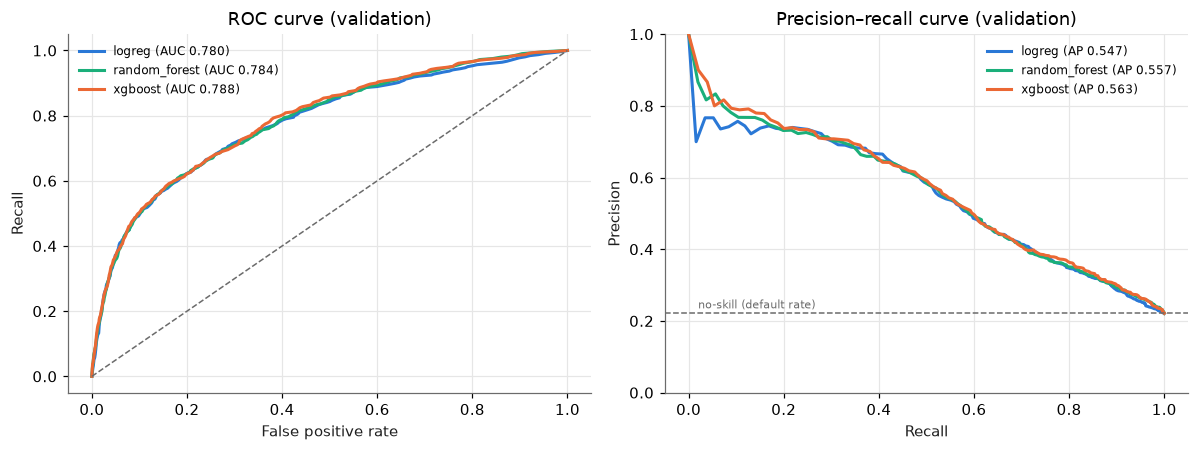

In [2]:
FAM = {"logreg": BLUE, "random_forest": AQUA, "xgboost": ORANGE}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for m, color in FAM.items():
    c = records[m]["curves"]; pm = records[m]["probability_metrics"]
    axes[0].plot(c["roc_fpr"], c["roc_tpr"], color=color, lw=2, label=f"{m} (AUC {pm['roc_auc']:.3f})")
    axes[1].plot(c["pr_recall"], c["pr_precision"], color=color, lw=2, label=f"{m} (AP {pm['pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
axes[0].set(title="ROC curve (validation)", xlabel="False positive rate", ylabel="Recall")
axes[1].axhline(0.2212, color=MUTED, ls="--", lw=1); axes[1].text(0.02, 0.235, "no-skill (default rate)", fontsize=7, color=MUTED)
axes[1].set(title="Precision–recall curve (validation)", xlabel="Recall", ylabel="Precision", ylim=(0, 1))
for ax in axes: ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "04_families_roc_pr.png", bbox_inches="tight")
pd.DataFrame({m: {**records[m]["cv"]["best_params"]} for m in ["random_forest", "xgboost"]}).T

In [3]:
fam_pairs = comparisons[comparisons.model_b.isin(["logreg", "random_forest", "logreg_raw", "dummy_prior"]) & ~comparisons.model_a.str.contains("__")]
fam_pairs[["model_a", "model_b", "metric", "difference", "low", "high", "p_value_two_sided"]]

,model_a,model_b,metric,difference,low,high,p_value_two_sided
0,logreg,logreg_raw,roc_auc,0.0066,0.0034,1.0193e-02,0.000
1,logreg,logreg_raw,pr_auc,0.0022,-0.0033,7.8787e-03,0.416
2,logreg,logreg_raw,brier,-0.0012,-0.0020,-5.3835e-04,0.000
3,logreg,dummy_prior,roc_auc,0.2798,0.2651,2.9376e-01,0.000
4,logreg,dummy_prior,pr_auc,0.3262,0.3005,3.5381e-01,0.000
5,logreg,dummy_prior,brier,-0.0377,-0.0420,-3.3348e-02,0.000
6,xgboost,logreg,roc_auc,0.0081,0.0023,1.3497e-02,0.002
7,xgboost,logreg,pr_auc,0.0158,0.0012,3.0241e-02,0.030
8,xgboost,logreg,brier,-0.0013,-0.0025,-8.5759e-05,0.036
9,xgboost,random_forest,roc_auc,0.0038,0.0011,6.4337e-03,0.004


## 2. Class-imbalance strategies

In [4]:
rows = []
for name, rec in records.items():
    if name in {"dummy_prior", "logreg_raw"} or "__" in name: continue
    base = rec["specification"].get("inherits_from") or name
    if rec["specification"]["estimator"] in {"easy_ensemble", "rusboost"}: base = "ensemble (own)"
    if rec["specification"]["estimator"] == "balanced_random_forest": base = "random_forest"
    pm = rec["probability_metrics"]; ci = rec["confidence_intervals"]
    rows.append({"model": name, "base": base, "strategy": strategy(name), "roc_auc": pm["roc_auc"], "pr_auc": pm["pr_auc"],
                 "pr_auc_low": ci["pr_auc"]["low"], "pr_auc_high": ci["pr_auc"]["high"], "brier": pm["brier"],
                 "ece": pm["expected_calibration_error"], "mean_pd": pm["mean_predicted_pd"],
                 "cv_ap": rec["cv"].get("cv_metrics_mean", {}).get("average_precision")})
strat = pd.DataFrame(rows).sort_values(["base", "pr_auc"], ascending=[True, False])
strat.set_index("model")

,base,strategy,roc_auc,pr_auc,pr_auc_low,pr_auc_high,brier,ece,mean_pd,cv_ap
model,,,,,,,,,,
easy_ensemble,ensemble (own),imbalance-aware ensemble,0.7799,0.5309,0.5028,0.5619,0.2078,0.2520,0.4727,0.5452
rusboost,ensemble (own),imbalance-aware ensemble,0.7705,0.5190,0.4918,0.5458,0.1647,0.1091,0.3302,0.5166
logreg,logreg,none,0.7798,0.5473,0.5192,0.5766,0.1345,0.0165,0.2184,0.5478
logreg_tomek_links,logreg,tomek_links,0.7790,0.5463,0.5180,0.5755,0.1352,0.0220,0.2371,0.5471
logreg_random_oversampling,logreg,random_oversampling,0.7793,0.5458,0.5179,0.5756,0.1805,0.2077,0.4289,0.5433
logreg_balanced,logreg,class weights,0.7800,0.5447,0.5164,0.5738,0.1799,0.2057,0.4268,0.5442
logreg_random_undersampling,logreg,random_undersampling,0.7801,0.5409,0.5116,0.5707,0.1801,0.2062,0.4274,0.5426
logreg_edited_nearest_neighbours,logreg,edited_nearest_neighbours,0.7783,0.5372,0.5082,0.5669,0.1633,0.1196,0.3391,0.5458
logreg_smotenc,logreg,smotenc,0.7670,0.5310,0.5004,0.5594,0.1820,0.1980,0.4192,0.5305


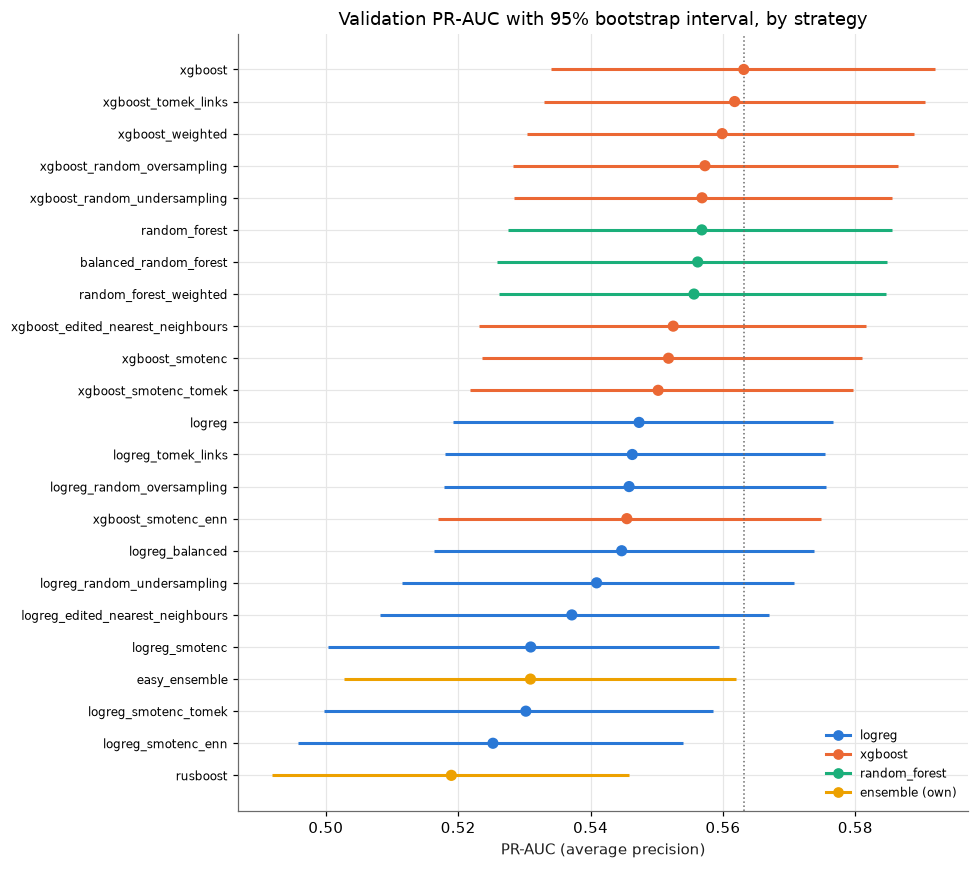

In [5]:
fig, ax = plt.subplots(figsize=(9, 8))
order = strat.sort_values("pr_auc")
colors = {"logreg": BLUE, "xgboost": ORANGE, "random_forest": AQUA, "ensemble (own)": YELLOW}
y = np.arange(len(order))
ax.hlines(y, order["pr_auc_low"], order["pr_auc_high"], color=[colors[b] for b in order["base"]], lw=2)
ax.scatter(order["pr_auc"], y, color=[colors[b] for b in order["base"]], s=40, zorder=3)
ax.set_yticks(y, order["model"], fontsize=8)
ax.axvline(records["xgboost"]["probability_metrics"]["pr_auc"], color=MUTED, ls=":", lw=1)
ax.set(title="Validation PR-AUC with 95% bootstrap interval, by strategy", xlabel="PR-AUC (average precision)")
ax.legend(handles=[plt.Line2D([], [], color=c, marker="o", lw=2) for c in colors.values()], labels=list(colors), frameon=False, fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(FIG_DIR / "04_strategies_pr_auc.png", bbox_inches="tight")

Overlapping marginal intervals don't by themselves show that two models are equivalent. The paired tests below remove the shared sampling noise.

In [6]:
comparisons[comparisons.model_a.eq("xgboost") | comparisons.model_a.eq("logreg")][["model_a", "model_b", "metric", "difference", "low", "high", "p_value_two_sided"]]

,model_a,model_b,metric,difference,low,high,p_value_two_sided
0,logreg,logreg_raw,roc_auc,0.0066,0.0034,1.0193e-02,0.000
1,logreg,logreg_raw,pr_auc,0.0022,-0.0033,7.8787e-03,0.416
2,logreg,logreg_raw,brier,-0.0012,-0.0020,-5.3835e-04,0.000
3,logreg,dummy_prior,roc_auc,0.2798,0.2651,2.9376e-01,0.000
4,logreg,dummy_prior,pr_auc,0.3262,0.3005,3.5381e-01,0.000
5,logreg,dummy_prior,brier,-0.0377,-0.0420,-3.3348e-02,0.000
6,xgboost,logreg,roc_auc,0.0081,0.0023,1.3497e-02,0.002
7,xgboost,logreg,pr_auc,0.0158,0.0012,3.0241e-02,0.030
8,xgboost,logreg,brier,-0.0013,-0.0025,-8.5759e-05,0.036
9,xgboost,random_forest,roc_auc,0.0038,0.0011,6.4337e-03,0.004


## 3. Discrimination vs calibration

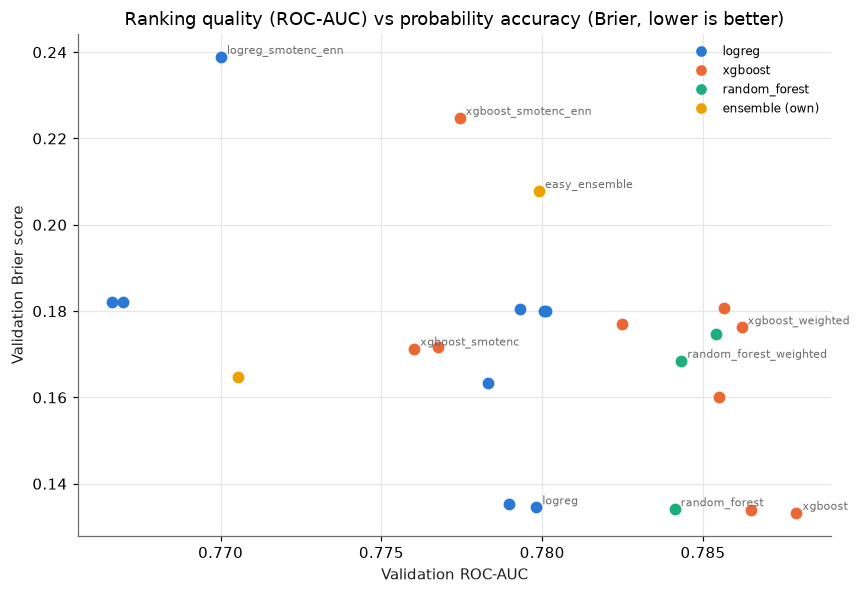

In [7]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for _, r in strat.iterrows():
    ax.scatter(r["roc_auc"], r["brier"], color=colors[r["base"]], s=45, zorder=3)
label_these = {"logreg", "random_forest", "xgboost", "xgboost_smotenc", "xgboost_weighted", "xgboost_smotenc_enn", "logreg_smotenc_enn", "random_forest_weighted", "easy_ensemble"}
for _, r in strat[strat["model"].isin(label_these)].iterrows():
    ax.annotate(r["model"], (r["roc_auc"], r["brier"]), fontsize=7, color=MUTED, xytext=(4, 2), textcoords="offset points")
ax.set(title="Ranking quality (ROC-AUC) vs probability accuracy (Brier, lower is better)", xlabel="Validation ROC-AUC", ylabel="Validation Brier score")
ax.legend(handles=[plt.Line2D([], [], color=c, marker="o", lw=0) for c in colors.values()], labels=list(colors), frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "04_auc_vs_brier.png", bbox_inches="tight")

In [8]:
strat.groupby("strategy")[["mean_pd", "ece", "brier", "roc_auc", "pr_auc"]].mean().sort_values("ece")

,mean_pd,ece,brier,roc_auc,pr_auc
strategy,,,,,
none,0.2186,0.0149,0.1339,0.7839,0.5558
tomek_links,0.2373,0.0205,0.1346,0.7827,0.5540
edited_nearest_neighbours,0.3395,0.1191,0.1617,0.7819,0.5448
imbalance-aware ensemble,0.4059,0.1849,0.1824,0.7786,0.5354
smotenc_tomek,0.4090,0.1879,0.1769,0.7717,0.5402
smotenc,0.4100,0.1888,0.1767,0.7715,0.5414
class weights,0.4147,0.1936,0.1749,0.7835,0.5534
random_oversampling,0.4242,0.2031,0.1788,0.7809,0.5515
random_undersampling,0.4276,0.2064,0.1803,0.7829,0.5489


## Robustness of the ranking: cross-validation vs validation

34 variants were compared on the same validation set, so the best validation score is optimistically biased (winner's curse). The table below sets the training-set CV estimate next to the validation estimate. The CV estimate is a second, independent check on the order of the models.


In [9]:
summary.loc[["logreg", "random_forest", "xgboost", "xgboost_weighted", "xgboost_tomek_links", "xgboost_smotenc", "xgboost_random_undersampling", "balanced_random_forest"],
             ["cv_average_precision", "cv_average_precision_std", "pr_auc", "cv_roc_auc", "roc_auc", "cv_brier", "brier"]]

,cv_average_precision,cv_average_precision_std,pr_auc,cv_roc_auc,roc_auc,cv_brier,brier
model,,,,,,,
logreg,0.5478,0.0144,0.5473,0.7835,0.7798,0.1345,0.1345
random_forest,0.5697,0.0150,0.5568,0.7855,0.7841,0.1327,0.1341
xgboost,0.5693,0.0175,0.5631,0.7878,0.7879,0.1326,0.1333
xgboost_weighted,0.5703,0.0174,0.5599,0.7881,0.7862,0.1756,0.1762
xgboost_tomek_links,0.5700,0.0188,0.5618,0.7882,0.7865,0.1332,0.1340
xgboost_smotenc,0.5571,0.0170,0.5518,0.7793,0.7760,0.1702,0.1713
xgboost_random_undersampling,0.5578,0.0168,0.5568,0.7865,0.7856,0.1821,0.1806
balanced_random_forest,0.5697,0.0173,0.5562,0.7863,0.7854,0.1744,0.1746


## Findings (validation set, 6,000 clients)

**1. Tree ensembles beat Logistic Regression. XGBoost vs Random Forest is not settled at this stage.**
- XGBoost beats Logistic Regression in both CV (PR-AUC 0.569 vs 0.548) and validation (paired ΔPR-AUC +0.016 [+0.001, +0.030]).
- Against Random Forest, XGBoost leads on validation (+0.006 [+0.001, +0.011]), but CV shows the two as equivalent (0.569 vs 0.570).
- Paired intervals are **not adjusted for the many comparisons made**, so the XGBoost vs Random Forest difference should not be over-interpreted. The final, one-time test evaluation (notebook 06) is the unbiased check.

**2. On this dataset and protocol, none of the tested class-imbalance methods improved discrimination over training on the original distribution.**
- No variant improves on its unmodified base model by more than the CV noise (fold standard deviation of PR-AUC ≈ 0.017).
- Class weights and Tomek links are indistinguishable from the base model (CV PR-AUC within ±0.001; validation slightly lower).
- SMOTE-NC, random undersampling and the hybrids are lower in both CV and validation.
- Several are significantly worse: SMOTE-NC (ΔPR-AUC −0.011), SMOTE-NC + ENN (−0.018), Balanced Random Forest (−0.007 vs XGBoost).
- This is an empirical result for these models and this data. It is **not** a general rule that a 22% default rate is too high for rebalancing to help. That depends on the model, the features, the strength of the signal and the sampler.

**3. Rebalancing distorts the PDs, and the cause is identified (see below).** Rebalanced models predict a mean PD of about 0.34–0.49 against an observed rate of 0.22 (ECE ≈ 0.12–0.27).

**4. Tomek links are almost neutral.** They remove few observations (about 6%), so the class prior barely moves.

## Why do the rebalancing methods fail here?

**(a) Miscalibration is a prior shift, and it can be verified exactly.**
- After balancing, the model learns odds that are too large by a factor of [π_s/(1−π_s)] / [π/(1−π)] = 1 / 0.284 ≈ 3.5, with π = 0.221 and π_s = 0.5.
- Dividing that factor out (`credit_risk.calibration.prior_correction`) fits no parameter on validation data. It still restores calibration almost completely (next cell).
- So the distortion is not noise. It is the predictable effect of training on the wrong class prior.


In [10]:
from credit_risk.calibration import prior_correction
from credit_risk.evaluation import probability_metrics
# the dummy model predicts the training default rate for every client
train_rate = records["dummy_prior"]["probability_metrics"]["mean_predicted_pd"]
rows = []
for name in ["xgboost_weighted", "xgboost_random_undersampling", "xgboost_random_oversampling", "xgboost_smotenc", "logreg_balanced", "logreg_smotenc", "balanced_random_forest"]:
    d = pd.read_csv(resolve_path(f"artifacts/predictions/validation_{name}.csv"))
    raw = probability_metrics(d["default_next_month"], d["pd"])
    cor = probability_metrics(d["default_next_month"], prior_correction(d["pd"], train_rate, 0.5))
    rows.append({"model": name, "mean_pd_raw": raw["mean_predicted_pd"], "mean_pd_corrected": cor["mean_predicted_pd"],
                 "ece_raw": raw["expected_calibration_error"], "ece_corrected": cor["expected_calibration_error"],
                 "brier_raw": raw["brier"], "brier_corrected": cor["brier"], "roc_auc": raw["roc_auc"]})
pd.DataFrame(rows).set_index("model")

,mean_pd_raw,mean_pd_corrected,ece_raw,ece_corrected,brier_raw,brier_corrected,roc_auc
model,,,,,,,
xgboost_weighted,0.4186,0.2100,0.1975,0.0185,0.1762,0.1338,0.7862
xgboost_random_undersampling,0.4278,0.2154,0.2067,0.0167,0.1806,0.1344,0.7856
xgboost_random_oversampling,0.4195,0.2100,0.1984,0.0192,0.1771,0.1344,0.7825
xgboost_smotenc,0.4008,0.1948,0.1797,0.0279,0.1713,0.1371,0.7760
logreg_balanced,0.4268,0.2188,0.2057,0.0127,0.1799,0.1348,0.7800
logreg_smotenc,0.4192,0.2145,0.1980,0.0143,0.1820,0.1379,0.7670
balanced_random_forest,0.4147,0.2094,0.1935,0.0152,0.1746,0.1344,0.7854


**(b) SMOTE-NC also damages the ranking. The evidence points to the synthetic interpolation itself.**
- Random oversampling (exact copies) and SMOTE-NC produce the same prior shift. Only SMOTE-NC loses ranking quality: ROC-AUC 0.776 vs 0.783, PR-AUC 0.552 vs 0.557.
- The extra loss therefore comes from the synthetic points, not from rebalancing as such.
- A plausible mechanism (a hypothesis, not proven here): the strongest signal is in the discrete repayment-status history. Interpolated defaulters with rounded monetary values and copied categorical codes populate regions where non-defaulters dominate, so the boosted trees learn spurious splits.

**(c) Reweighting cannot add ranking information.** Class weights and random resampling change how much each error counts, not which clients rank above others. Their ROC-AUC stays within ±0.003 of the base model. Any effect on recall can be reproduced by moving the threshold of the unweighted, calibrated model.

These conclusions apply to this dataset and protocol. They do not show that resampling never helps, for example with much rarer default events, weaker models, or very small training sets.